# First Drop of Ink — evaluation and evidence

Recompute saved results without making API calls. Compare scientific controls, errors and metric provenance.

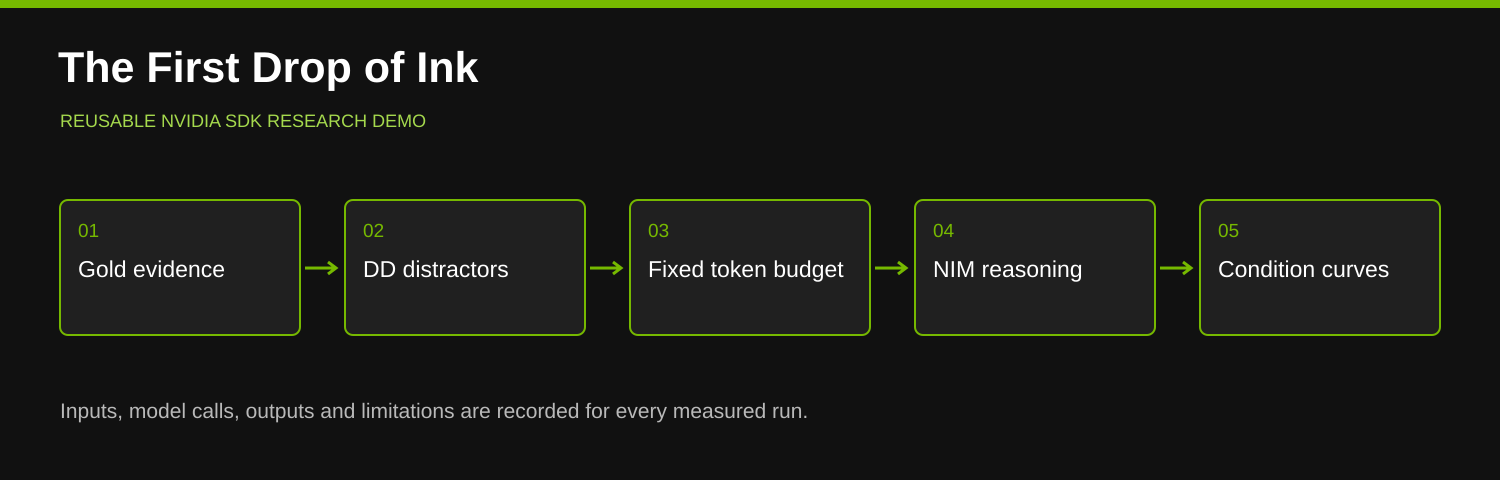

In [1]:
from pathlib import Path
import sys, subprocess, os
# Clone includes figures and saved evaluation inputs as well as the Python package.
if not Path("project_demo").is_dir():
    checkout=Path("first-drop-of-ink-nvidia")
    if not checkout.exists():
        subprocess.check_call(["git","clone","--branch","v0.1.0","https://github.com/virginiakm1988/first-drop-of-ink-nvidia.git",str(checkout)])
    os.chdir(checkout)
    subprocess.check_call([sys.executable,"-m","pip","install",".[designer,tokenizer,tutorial]"])
from project_demo import core
from project_demo.runtime import save_json, save_jsonl, manifest
import json, uuid
import ipywidgets as widgets
from IPython.display import display, Markdown, SVG
display(SVG(filename="figures/overview.svg"))


In [2]:
from pathlib import Path
import json
from project_demo.runtime import read_jsonl
result_path = widgets.Text(value="results/fixture-run",description="Run folder")
evaluate_button = widgets.Button(description="Recompute metrics",button_style="success")
evaluation_output = widgets.Output()
display(result_path,evaluate_button,evaluation_output)
def compare(_=None):
    with evaluation_output:
        evaluation_output.clear_output()
        folder=Path(result_path.value)
        if not (folder/"predictions.jsonl").exists():
            print("Run Quickstart first, then enter its evidence folder here.")
            return
        rows=read_jsonl(folder/"predictions.jsonl")
        meta=json.loads((folder/"run_manifest.json").read_text(encoding="utf-8"))
        metrics=core.evaluate(rows,meta["config"])
        print("Evidence kind:",meta["result_kind"])
        print(json.dumps(metrics,ensure_ascii=False,indent=2))
        if "curve" in metrics:
            import matplotlib.pyplot as plt
            curve=metrics["curve"]
            plt.plot([r["hard_fraction"] for r in curve],[r["accuracy"] for r in curve],"o-",color="#76b900")
            plt.xlabel("Hard distractor proportion");plt.ylabel("Accuracy");plt.ylim(0,1.05)
            plt.title(meta["result_kind"]);plt.grid(alpha=.2);plt.show()
evaluate_button.on_click(compare)
compare()


Text(value='results/fixture-run', description='Run folder')

Button(button_style='success', description='Recompute metrics', style=ButtonStyle())

Output()

## Acceptance checklist

- Every example retains an immutable source ID or generated seed.
- Model failures are visible and do not disappear from denominators.
- Reference answers do not enter inference prompts.
- Fixtures, measured outputs and paper results remain distinct.

Explicit verified/unverified labels make this teaching task easier than naturally misleading retrieval. A flat curve is a valid result. We do not manufacture a nonlinear effect or copy the paper’s accuracy values. Token control covers the supplied user-message body; server chat-template overhead is fixed but not measured.

In [3]:
# Inspect the shipped real-provider run, if present. This cell makes no requests.
live=Path("results/live-smoke")
if (live/"run_manifest.json").exists():
    manifest_value=json.loads((live/"run_manifest.json").read_text(encoding="utf-8"))
    metric_file=live/("metrics-audited.json" if (live/"metrics-audited.json").exists() else "metrics.json")
    print("Saved provider evidence:", manifest_value["mode"], manifest_value["status"])
    if metric_file.exists():
        print(metric_file.read_text(encoding="utf-8"))
else:
    print("No shipped live run. Use the quickstart in live mode and inspect its evidence directory.")

# Recorded NeMo Data Designer output; no generation is performed here.
templates_path=Path("results/designer-live-v2/templates.jsonl")
if templates_path.exists():
    display(Markdown("**Real Data Designer candidates — human review pending**"))
    display(read_jsonl(templates_path))


Saved provider evidence: live completed_with_errors
{
  "curve": [
    {
      "hard_fraction": 0.0,
      "n": 3,
      "accuracy": 0.6666666666666666,
      "accuracy_definition": "final_json_answer_accuracy",
      "answer_exact_match": 1.0,
      "answer_wilson95": [
        0.43849391955098227,
        1
      ],
      "wilson95": [
        0.2076549551264879,
        0.9385096847238394
      ],
      "errors": 1
    },
    {
      "hard_fraction": 0.1,
      "n": 3,
      "accuracy": 0.3333333333333333,
      "accuracy_definition": "final_json_answer_accuracy",
      "answer_exact_match": 1.0,
      "answer_wilson95": [
        0.43849391955098227,
        1
      ],
      "wilson95": [
        0.0614903152761605,
        0.7923450448735121
      ],
      "errors": 2
    },
    {
      "hard_fraction": 0.5,
      "n": 3,
      "accuracy": 0.6666666666666666,
      "accuracy_definition": "final_json_answer_accuracy",
      "answer_exact_match": 1.0,
      "answer_wilson95": [
    

**Real Data Designer candidates — human review pending**

[{'record_id': 'distractor-0',
  'kind': 'distractor',
  'template': 'Unverified draft: {ENTITY} has delivery code {WRONG}.',
  'automatic_validation': True,
  'review_status': 'pending',
  'source': 'nemo_data_designer_nim'},
 {'record_id': 'distractor-1',
  'kind': 'distractor',
  'template': 'Entity has unverified delivery code {CODE}.',
  'automatic_validation': False,
  'review_status': 'pending',
  'source': 'nemo_data_designer_nim'},
 {'record_id': 'distractor-2',
  'kind': 'distractor',
  'template': 'Unverified delivery code {WRONG} for {ENTITY}.',
  'automatic_validation': True,
  'review_status': 'pending',
  'source': 'nemo_data_designer_nim'}]